# 8-1. Stable Diffusion 이미지 생성 및 인페인팅 실습

텍스트로 이미지를 생성하고, 정상 이미지의 지정 영역을 편집하는 과정을 실습한다. 이후 같은 해변 이미지에서 마스크 크기만 변경해 객체 생성과 배경 보존의 차이를 비교한다. 별도의 모델 학습은 수행하지 않고 사전학습 모델을 이용한다.

**진행 흐름:** 환경 확인 → 텍스트 기반 생성 → 단순 배경 인페인팅 → 실제 사진 인페인팅 → 기본 결과 분석 및 추가 실험 설계 → 마스크 크기 비교 → 최종 결과 분석.

기존 실행 이미지와 로그를 유지하고 기능별로 코드 셀을 나눴다. 표시된 실행 번호는 분할 전 원본 셀의 실행 기록에 해당한다.

## 1. 실행 환경과 공통 기능 준비

`diffusers`와 `transformers` 버전을 확인하고, CUDA 사용 가능 여부에 따라 실행 장치를 정한다. 이미지 생성 파이프라인, PIL 이미지 처리와 Matplotlib 출력 함수를 준비한다.

아래 설치 명령은 모두 주석 상태이므로 실행되지 않는다. 저장된 실행 결과는 `diffusers 0.40.0`, `transformers 5.18.0`, CUDA 사용을 보여준다. 주석에 적힌 버전과 실제 실행 버전을 구분한다.

첫 번째 `display_image` 함수는 이미지를 출력하고 축을 숨긴다. 뒤의 해변 실습에서는 제목도 표시하는 함수로 다시 정의한다.

In [ ]:
# !pip install diffusers transformers accelerate torch torchvision

In [ ]:
import diffusers
import transformers

diffusers.__version__

'0.40.0'

In [ ]:
transformers.__version__

'5.18.0'

In [ ]:
# !pip install diffusers==0.33.1
# !pip install transformers==4.52.4

In [ ]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [ ]:
from diffusers import StableDiffusionPipeline, StableDiffusionInpaintPipeline
from PIL import Image
import matplotlib.pyplot as plt

def display_image(image):
    plt.imshow(image)
    plt.axis('off')
    plt.show()

## 2. 텍스트 기반 이미지 생성

### 모델과 생성 조건 설정

`runwayml/stable-diffusion-v1-5`를 GPU에 로딩하고 텍스트 프롬프트를 준비한다. 프롬프트는 달에서 우주복을 입고 말을 타는 사람을 요구한다. 제외할 표현은 negative prompt로 전달하며, 생성 스텝은 30, guidance scale은 8.5로 설정한다.

시드 42의 generator를 만들지만, 실제 호출의 `generator=generator`가 주석 처리되어 있어 이 기본 예제에는 시드 고정이 적용되지 않는다. 뒤의 마스크 비교 실험은 generator를 명시적으로 전달해 시드를 고정한다.

In [ ]:
# --- 1.1 파이프라인 로드 ---
model_id_text2img = "runwayml/stable-diffusion-v1-5"
pipe_text2img = StableDiffusionPipeline.from_pretrained(model_id_text2img, torch_dtype=torch.float16)
pipe_text2img = pipe_text2img.to(device)
print("Text-to-Image pipeline loaded.")

# --- 1.2 프롬프트 정의 및 이미지 생성 ---
prompt_defect = "A photo of man riding a horse in the moon wearing astronaut outfits"
negative_prompt = "blurry, deformed, cartoon, painting, illustration, normal, no defect"

# 파라미터 설정
num_steps = 30
guidance_scale_val = 8.5
num_images_per_prompt = 1 # 한 번에 여러 개 생성 가능

print(f"Generating image for prompt: '{prompt_defect}'")
# seed 고정으로 재현성 확보 (선택 사항)
generator = torch.Generator(device=device).manual_seed(42)



Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Text-to-Image pipeline loaded.
Generating image for prompt: 'A photo of man riding a horse in the moon wearing astronaut outfits'


### 이미지 생성과 결과 확인

설정한 프롬프트로 이미지 한 장을 생성한 뒤 출력하고 `generated_defect_0.png`로 저장한다. 파일명에 `defect`가 들어가지만 이 단계의 실제 내용은 일반 이미지 생성이다. 이미지 파일이 생성됐는지와 프롬프트의 모든 조건이 구현됐는지는 별도로 확인한다.

In [ ]:
with torch.autocast("cuda"): # float16 연산 시
    generated_images = pipe_text2img(
        prompt_defect,
        negative_prompt=negative_prompt,
        num_inference_steps=num_steps,
        guidance_scale=guidance_scale_val,
        num_images_per_prompt=num_images_per_prompt,
        # generator=generator
    ).images



  0%|          | 0/30 [00:00<?, ?it/s]

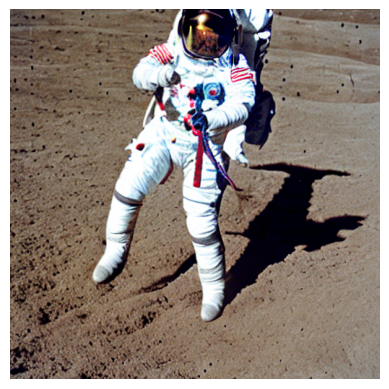

Image saved as generated_defect_0.png


In [ ]:
# --- 1.3 결과 확인 및 저장 ---
for i, image in enumerate(generated_images):
    display_image(image)
    try:
        image.save(f"generated_defect_{i}.png")
        print(f"Image saved as generated_defect_{i}.png")
    except Exception as e:
        print(f"Error saving image: {e}")


## 3. 단순 배경의 지정 영역 편집

### 인페인팅 모델과 입력 준비

SD 1.5 기반 인페인팅 모델을 로딩한다. 회색 RGB 이미지와 검은색 마스크를 각각 512×512로 만들고, 마스크 중앙에 흰색 원을 그린다. 흰색 부분이 편집 대상이고 검은색 부분은 보존하도록 지정한 영역이다.

모델을 불러오지 못하면 `pipe_inpaint=None`으로 설정해 이후 단계를 건너뛰도록 되어 있다. 기록에는 모델 로딩과 결과 저장이 완료되어 있다.

In [ ]:
# --- 2.1 파이프라인 로드 ---
# Inpainting 전용 모델 사용
model_id_inpaint = "stable-diffusion-v1-5/stable-diffusion-inpainting" # 또는 다른 inpainting 모델
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(model_id_inpaint, torch_dtype=torch.float16)
    pipe_inpaint = pipe_inpaint.to(device)
    print("Inpainting pipeline loaded.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}. Skipping inpainting part or use a general pipeline.")
    pipe_inpaint = None # 예외 처리



Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Inpainting pipeline loaded.


Using placeholder initial image and mask.


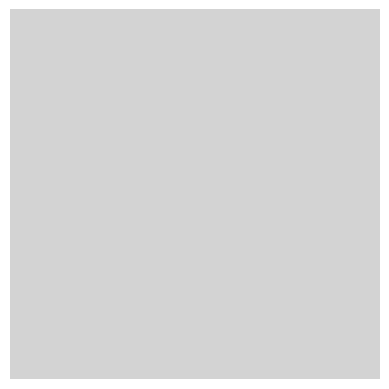

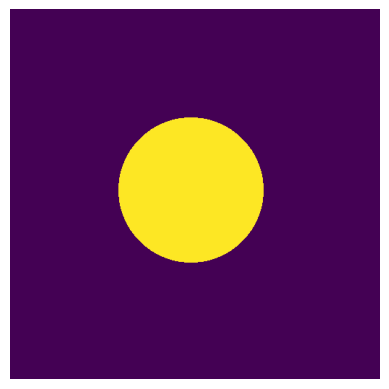

In [ ]:
if pipe_inpaint:
    # --- 2.2 원본 이미지 및 마스크 준비 ---
    init_image = Image.new("RGB", (512, 512), "lightgray") # 밝은 회색 배경
    mask_image = Image.new("L", (512, 512), "black")
    from PIL import ImageDraw
    draw = ImageDraw.Draw(mask_image)
    draw.ellipse(((150, 150), (350, 350)), fill="white") # 중앙 흰색 원형 마스크
    print("Using placeholder initial image and mask.")
    display_image(init_image)
    display_image(mask_image)




### 움푹 팬 자국 생성 시도와 출력

`A deep circular dent with rough edges`를 입력해 중앙에 깊고 거친 원형 자국을 만들도록 요청한다. 생성 스텝은 50, guidance scale은 7.5이다. 결과는 출력한 뒤 `inpainted_defect_0.png`로 저장한다.

이 단계에서는 위치를 지정하는 마스크와 어떤 내용을 생성할지 지정하는 프롬프트의 역할을 구분해 확인한다.

In [ ]:
if pipe_inpaint:
    # --- 2.3 프롬프트 정의 및 이미지 생성 ---
    prompt_inpaint_defect = "A deep circular dent with rough edges"
    negative_prompt_inpaint = "smooth, perfect, flat, no dent, blurry"

    print(f"Inpainting with prompt: '{prompt_inpaint_defect}'")
    with torch.autocast("cuda"):
        inpainted_images = pipe_inpaint(
            prompt=prompt_inpaint_defect,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt_inpaint,
            num_inference_steps=50, # Inpainting은 조금 더 많은 step이 필요할 수 있음
            guidance_scale=7.5
        ).images



Inpainting with prompt: 'A deep circular dent with rough edges'


  0%|          | 0/50 [00:00<?, ?it/s]

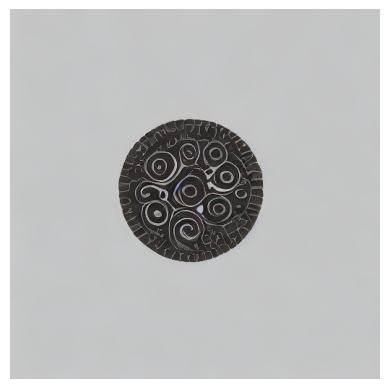

Image saved as inpainted_defect_0.png


In [ ]:
if pipe_inpaint:
    # --- 2.4 결과 확인 및 저장 ---
    for i, image in enumerate(inpainted_images):
        display_image(image)
        try:
            image.save(f"inpainted_defect_{i}.png")
            print(f"Image saved as inpainted_defect_{i}.png")
        except Exception as e:
            print(f"Error saving image: {e}")

# TODO: 다양한 원본 이미지, 마스크, 프롬프트로 실험해보세요!
#       예: 실제 정상 제품 이미지에 사용자가 직접 그린 마스크 적용

## 4. 실제 해변 사진에 객체 추가

### 모델과 표시 함수 준비

해변 실습을 위한 라이브러리와 장치를 준비하고, 제목을 표시하는 `display_image` 함수를 정의한다. 같은 인페인팅 모델을 다시 로딩하며 CUDA에서는 float16, CPU에서는 float32를 선택한다.

단순 배경의 편집에서 실제 사진의 문맥을 유지하며 객체를 추가하는 실습으로 확장한다.

In [ ]:
import torch
from diffusers import StableDiffusionInpaintPipeline
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import requests
from io import BytesIO

# --- 1. 디바이스 설정 ---
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# --- 2. 이미지 시각화 함수 ---
def display_image(image, title="Generated Image"):
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(title)
    plt.axis('off')
    plt.show()

# --- 3. 파이프라인 로딩 ---
model_id_inpaint = "stable-diffusion-v1-5/stable-diffusion-inpainting"
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
        model_id_inpaint,
        torch_dtype=torch.float16 if device == "cuda" else torch.float32
    )
    pipe_inpaint = pipe_inpaint.to(device)
    print(f"Inpainting pipeline loaded with {model_id_inpaint}.")
except Exception as e:
    print(f"Could not load inpainting pipeline: {e}")
    pipe_inpaint = None

# --- 4. 이미지와 마스크 준비 ---


Using device: cuda


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Inpainting pipeline loaded with stable-diffusion-v1-5/stable-diffusion-inpainting.


### 해변 이미지, 마스크와 프롬프트 설정

Unsplash 해변 사진을 내려받아 512×512로 맞춘다. 다운로드가 실패하면 직접 그린 대체 배경을 사용하도록 되어 있으며, 현재 실행 기록에서는 실제 해변 사진을 정상적으로 불러왔다.

중앙의 타원형 마스크는 `ellipse_box=[106, 56, 406, 456]`으로 지정한다. 가로 길이는 300, 세로 길이는 400이다. 프롬프트는 `A treasure chest buried in the sand`, 시드는 1234로 설정한다.

Image loaded and resized to 512x512.


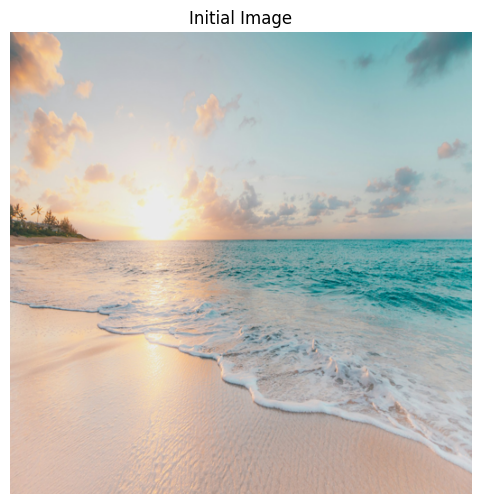

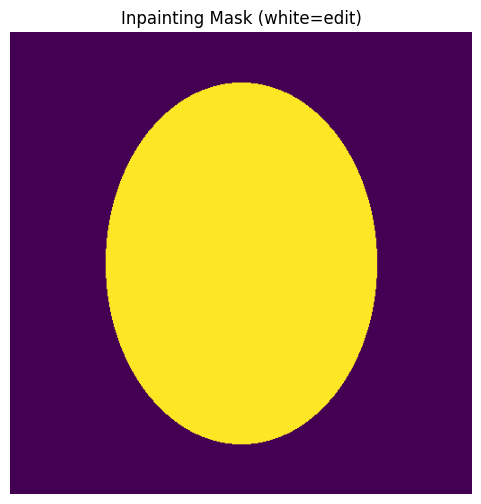

Running inpainting with prompt: A treasure chest buried in the sand


In [ ]:
if pipe_inpaint:
    # 이미지 로드
    image_url = "https://images.unsplash.com/photo-1507525428034-b723cf961d3e?q=80&w=2070&auto=format&fit=crop"
    try:
        response = requests.get(image_url)
        response.raise_for_status()
        init_image = Image.open(BytesIO(response.content)).convert("RGB").resize((512, 512))
        print("Image loaded and resized to 512x512.")
    except Exception as e:
        print(f"Image load failed: {e}. Using placeholder image.")
        init_image = Image.new("RGB", (512, 512))
        draw = ImageDraw.Draw(init_image)
        draw.rectangle([0, 0, 512, 280], fill="skyblue")
        draw.rectangle([0, 280, 512, 512], fill="goldenrod")
        draw.ellipse([400, 60, 440, 100], fill="gold")

    # 마스크 생성 (중앙 타원형)
    mask_image = Image.new("L", (512, 512), 0)  # 검정 배경
    draw = ImageDraw.Draw(mask_image)
    ellipse_box = [106, 56, 406, 456]  # 대략 중앙 타원 (너비 300, 높이 400)
    draw.ellipse(ellipse_box, fill=255)  # 흰색 영역을 인페인팅할 영역으로

    # 이미지 확인
    display_image(init_image, "Initial Image")
    display_image(mask_image, "Inpainting Mask (white=edit)")

    # --- 5. 프롬프트 정의 ---
    prompt = "A treasure chest buried in the sand"
    negative_prompt = "blurry, deformed, cartoon, illustration, watermark, text, signature, extra limbs"

    print(f"Running inpainting with prompt: {prompt}")

    generator = torch.Generator(device=device).manual_seed(1234)



### 인페인팅 실행과 결과 저장

같은 원본 이미지, 마스크, 프롬프트를 전달해 보물상자를 생성한다. 생성 스텝 50, guidance scale 8.5를 사용하며, 결과는 `result_inpainted_0.png`로 저장한다.

입력 사진과 마스크가 각각 출력되고, 그 다음에 생성 결과가 표시된다. 이후 추가 실험에서도 이 해변 사진과 프롬프트를 그대로 사용한다.

In [ ]:
if pipe_inpaint:
    # --- 6. 인페인팅 수행 ---
    if device == "cuda":
        with torch.autocast("cuda"):
            result = pipe_inpaint(
                prompt=prompt,
                image=init_image,
                mask_image=mask_image,
                negative_prompt=negative_prompt,
                guidance_scale=8.5,
                num_inference_steps=50,
                generator=generator
            )
    else:
        result = pipe_inpaint(
            prompt=prompt,
            image=init_image,
            mask_image=mask_image,
            negative_prompt=negative_prompt,
            guidance_scale=8.5,
            num_inference_steps=50,
            generator=generator
        )



  0%|          | 0/50 [00:00<?, ?it/s]

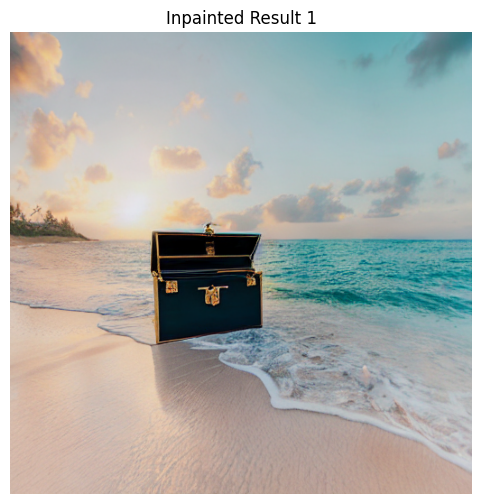

Saved: result_inpainted_0.png


In [ ]:
if pipe_inpaint:
    # --- 7. 결과 출력 및 저장 ---
    if result and result.images:
        for i, out_img in enumerate(result.images):
            display_image(out_img, f"Inpainted Result {i+1}")
            out_img.save(f"result_inpainted_{i}.png")
            print(f"Saved: result_inpainted_{i}.png")
    else:
        print("No images returned from inpainting.")

else:
    print("Pipeline not loaded. Cannot run inpainting.")


## 5. 기본 실습 결과 분석과 추가 실험 설계

### 기존 코드의 결과 분석

| 단계 | 의도한 결과 | 실제 관찰 |
|---|---|---|
| 텍스트 기반 생성 | 달에서 우주복을 입고 말을 타는 사람 | 우주복을 입은 인물과 지면은 표현됐지만, 말과 승마 동작은 명확하지 않았다. |
| 회색 배경 인페인팅 | 중앙의 깊고 거친 원형 함몰 | 지정 영역에 검은 원형 물체와 반복 문양이 나타났다. 깊게 파인 자국으로 해석하기는 어려웠다. |
| 해변 인페인팅 | 모래에 묻힌 보물상자 | 열린 보물상자가 해변에 생성됐다. 다만 모래에 묻힌 모습보다는 모래 위에 놓인 모습에 가까웠다. |

세 단계에서 이미지 출력과 저장은 완료됐다. 그러나 실행 성공과 프롬프트의 의미를 정확히 구현한 것은 구분해야 한다. 편집 위치를 지정해도 요청한 형태와 세부 상황이 모두 표현되지는 않았다.

해변의 기본 결과에서는 보물상자를 생성할 수 있었으므로, 다음에는 객체 생성과 주변 장면의 변화가 마스크 범위에 따라 어떻게 달라지는지 확인한다.

### 추가 실험 1: 마스크 크기 비교 계획

**질문:** 같은 해변 사진과 프롬프트를 사용할 때 마스크 크기가 보물상자 생성 여부, 객체 크기 및 주변 풍경에 어떤 영향을 미치는가?

| 구분 | 설정 |
|---|---|
| 변경할 조건 | 기존 마스크의 가로·세로 길이 배율: 0.5, 1.0, 1.2 |
| 고정할 조건 | 해변 사진, 마스크 중심, 기본·negative 프롬프트, 시드 1234, 생성 스텝 50, guidance scale 8.5 |
| 결과 수 | 조건별 1장, 총 3장 |
| 비교 기준 | 보물상자 유무, 형태와 크기, 주변 구름·바다·모래의 변화, 모래에 묻혔다는 조건의 표현 |

원래 타원의 중심은 유지하고 가로·세로 길이만 바꾼다. 배율이 0.5이면 면적은 약 0.25배, 1.2이면 약 1.44배가 되므로, 길이 배율과 면적 배율을 구분한다.

작은 마스크에서는 객체를 표현할 공간이 부족할 수 있고, 큰 마스크에서는 주변 풍경까지 달라질 수 있다는 가설을 둔다. 결과는 원본·마스크·생성 이미지 순서로 나란히 놓고 관찰한다. 각 조건마다 같은 시드로 generator를 새로 만들어 비교한다.

## 6. 추가 실험 1: 마스크 크기에 따른 생성 결과 비교

### 비교 조건과 출력 틀 준비

기존 `ellipse_box`에서 마스크 중심과 가로·세로 길이를 계산한다. 원본을 덮어쓰지 않도록 `exp1_` 변수로 실험 조건을 만들고, 세 조건을 비교할 3×3 출력 틀을 준비한다.

In [ ]:
exp1_scales = [0.5, 1.0, 1.2]

exp1_cx = (ellipse_box[0] + ellipse_box[2]) / 2
exp1_cy = (ellipse_box[1] + ellipse_box[3]) / 2
exp1_width = ellipse_box[2] - ellipse_box[0]
exp1_height = ellipse_box[3] - ellipse_box[1]

exp1_fig, exp1_axes = plt.subplots(3, 3, figsize=(12, 12))



### 조건별 생성과 비교표 출력

각 배율에 맞는 새 타원형 마스크를 만들고 기존 `pipe_inpaint`로 이미지를 생성한다. 원본 해변 사진과 프롬프트를 재사용하고, 각 호출에 시드 1234를 전달한다. 왼쪽부터 원본 사진, 실제 사용한 마스크, 생성 결과를 표시한다.

In [ ]:
for exp1_row, exp1_scale in enumerate(exp1_scales):
    exp1_w = exp1_width * exp1_scale
    exp1_h = exp1_height * exp1_scale

    exp1_mask = Image.new("L", init_image.size, 0)
    ImageDraw.Draw(exp1_mask).ellipse(
        [
            exp1_cx - exp1_w / 2, exp1_cy - exp1_h / 2,
            exp1_cx + exp1_w / 2, exp1_cy + exp1_h / 2,
        ],
        fill=255,
    )

    exp1_result = pipe_inpaint(
        prompt=prompt,
        image=init_image.copy(),
        mask_image=exp1_mask,
        negative_prompt=negative_prompt,
        guidance_scale=8.5,
        num_inference_steps=50,
        generator=torch.Generator(device=device).manual_seed(1234),
    ).images[0]

    for exp1_col, (exp1_show, exp1_title) in enumerate([
        (init_image, "Original"),
        (exp1_mask, f"Mask size x{exp1_scale}"),
        (exp1_result, "Generated"),
    ]):
        exp1_axes[exp1_row, exp1_col].imshow(exp1_show, cmap="gray")
        exp1_axes[exp1_row, exp1_col].set_title(exp1_title)
        exp1_axes[exp1_row, exp1_col].axis("off")



  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

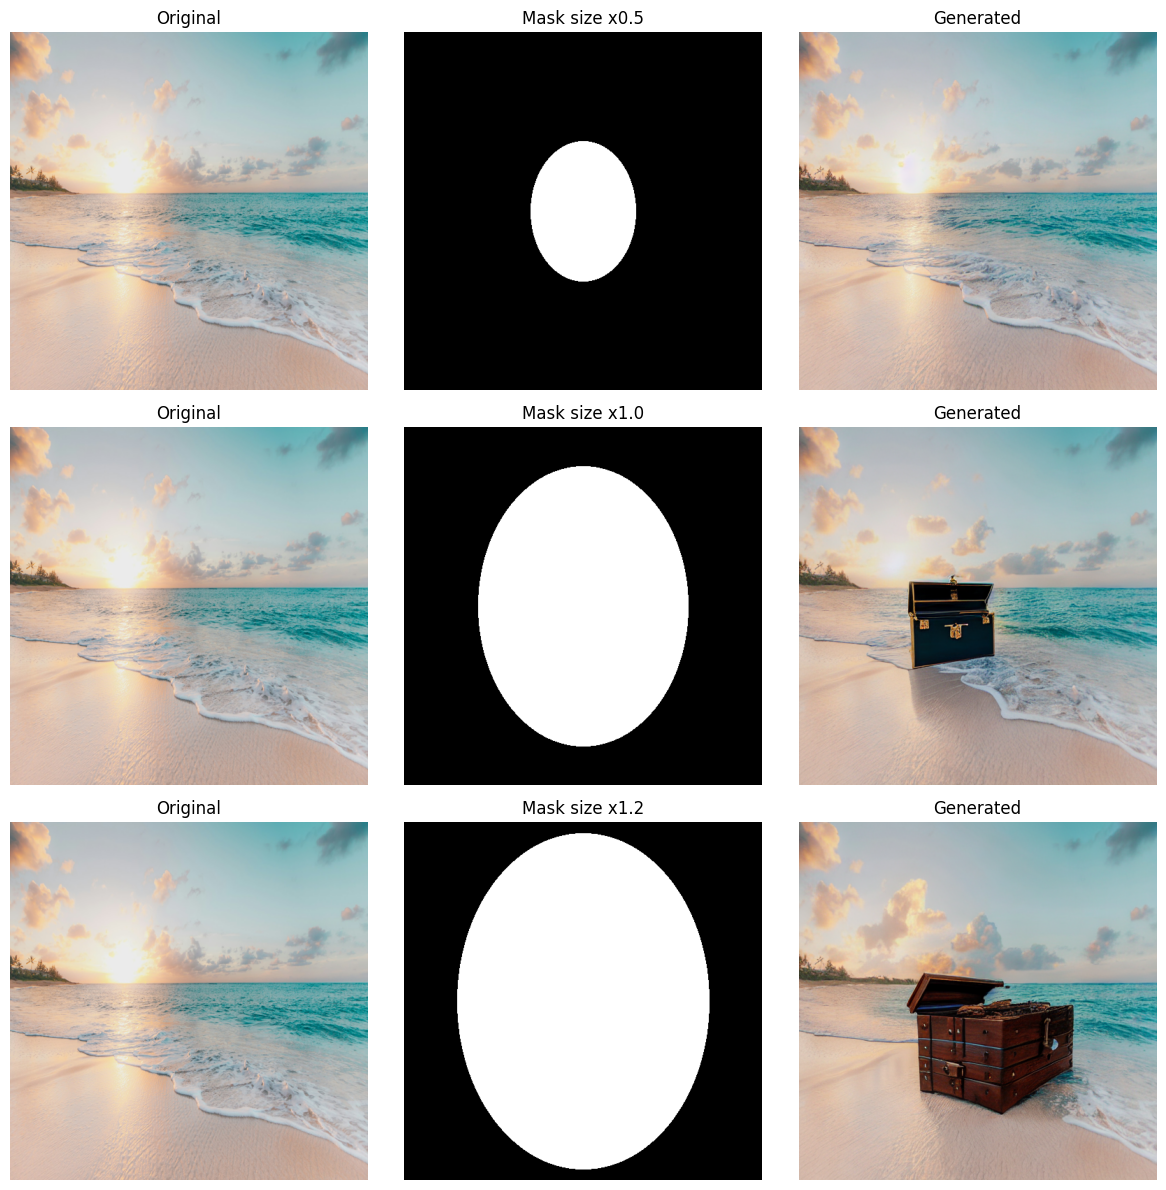

In [ ]:
exp1_fig.tight_layout()
plt.show()

## 7. 마지막 실험 결과 분석

| 마스크 가로·세로 배율 | 객체 생성 및 형태 | 주변 장면의 변화 |
|---|---|---|
| 0.5배 | 뚜렷한 보물상자가 보이지 않았다. | 원본과 유사한 해변 장면이 유지됐다. |
| 1.0배 | 열린 보물상자가 생성됐다. | 전체 해변 구도는 비교적 유지됐지만 구름과 편집 영역 내부의 장면에는 변화가 있었다. |
| 1.2배 | 더 큰 나무 상자가 생성됐고 형태도 달라졌다. | 모래와 구름 등 주변 장면이 더 넓게 달라졌다. |

이번 이미지와 시드에서는 1.0배 마스크가 객체 생성과 배경 보존 사이에서 가장 균형이 좋았다. 0.5배에서는 객체가 생성되지 않았고, 1.2배에서는 객체가 더 크게 생성되면서 장면의 변화도 커졌다. 작은 마스크에서 객체가 사라진 원인을 마스크 크기 하나로 확정할 수는 없지만, 크기에 따라 출력 양상이 달라진 것은 확인했다.

마스크는 편집할 공간을 지정하는 조건이지만 원하는 객체의 생성 여부와 정확한 형태까지 보장하지는 않았다. 보물상자가 생성된 조건에서도 ‘모래에 묻힌’ 모습은 충분히 표현되지 않았다. 따라서 이번 실험의 성과는 목표 장면을 완벽하게 구현한 것이 아니라, 마스크 범위에 따른 객체 생성과 장면 보존의 차이를 관찰한 데 있다.

이번 해변 이미지와 시드 1234에서는 비교한 세 조건 중 1.0배 마스크가 보물상자 생성과 주변 장면 보존 사이에서 가장 균형이 좋았다.